# Random forest

Một cây quyết định rất nhạy với dữ liệu: đổi vài mẫu huấn luyện là ngưỡng ở các nút có thể đổi, và dự đoán đổi theo. Random forest huấn luyện nhiều cây, mỗi cây trên một bản lấy mẫu khác của dữ liệu và chỉ xét một phần đặc trưng ở mỗi nút, rồi gộp dự đoán của các cây. Bài này giải thích vì sao gộp nhiều cây giúp dự đoán ổn định hơn, và vì sao các cây phải khác nhau thì gộp mới có tác dụng.

> **Mục tiêu**
>
> - Hiểu bootstrap và việc chọn ngẫu nhiên đặc trưng ở mỗi nút.
> - Tính điểm OOB.
> - Chọn số cây, độ sâu; đọc feature importance.

## Vì sao trung bình giúp ích

Bài 2.5 kết luận cây có variance cao: đổi dữ liệu một chút là cây đổi hẳn. Giả sử có $B$ mô hình, mỗi cái có phương sai $\sigma^2$, và hai mô hình bất kỳ có hệ số tương quan $\rho$. Phương sai của trung bình là

$$\operatorname{Var}\!\left(\frac{1}{B}\sum_{b=1}^{B} f_b\right) = \rho\,\sigma^2 + \frac{1 - \rho}{B}\,\sigma^2.$$

Khi $B \to \infty$, số hạng thứ hai biến mất nhưng số hạng đầu thì còn nguyên. Nhiều cây hơn chỉ giúp đến một mức; muốn giảm tiếp thì phải làm các cây **ít giống nhau** hơn, tức giảm $\rho$.

Với $\sigma^2 = 1$ và $B = 100$: nếu $\rho = 0.5$ thì phương sai còn $0.505$; nếu $\rho = 0.1$ thì còn $0.109$. Giảm tương quan có lợi hơn nhiều so với thêm cây. Khi $\rho = 0$ thì phương sai chia đều cho $B$: chụp 8 tấm cùng một cảnh tối rồi lấy trung bình từng điểm ảnh, nhiễu ngẫu nhiên triệt tiêu bớt còn cảnh đứng yên được giữ nguyên.



**Hỏi nhanh.** Lấy $\sigma^2 = 1$. Rừng A có 50 cây, $\rho = 0.1$. Rừng B có 500 cây, $\rho = 0.4$. Theo công thức trên, rừng nào có phương sai của trung bình nhỏ hơn?

- A. A, vì tương quan thấp quan trọng hơn số cây
- B. B, vì nhiều cây gấp mười lần
- C. Bằng nhau, vì cả hai đều đã đủ nhiều cây
- D. Chưa so được khi chưa biết $\sigma^2$ thật

<details><summary>Đáp án</summary>

A. A, vì tương quan thấp quan trọng hơn số cây

Rừng A có $0.1 + 0.9/50 \approx 0.118$, rừng B có $0.4 + 0.6/500 \approx 0.401$. Thêm cây chỉ xóa được phần $\frac{1-\rho}{B}$, còn phần $\rho\sigma^2$ thì vẫn nguyên. Hai rừng có cùng $\sigma^2$, nên kết quả so sánh không phụ thuộc vào giá trị cụ thể của nó.

</details>

## Hai nguồn ngẫu nhiên

Random forest (Breiman, 2001) làm các cây khác nhau bằng hai cách:

1. **Bagging** (bootstrap aggregating): mỗi cây học trên một tập bootstrap, tức $n$ mẫu rút có hoàn lại từ $n$ mẫu gốc.
2. **Chọn ngẫu nhiên đặc trưng** ở mỗi nút: chỉ xét một tập con ngẫu nhiên gồm `max_features` đặc trưng khi tìm phép chia tốt nhất. Nếu có một đặc trưng rất mạnh, bagging thuần túy vẫn cho mọi cây chia ở gốc bằng đặc trưng đó và các cây vẫn giống nhau. Che bớt đặc trưng buộc các cây phải tìm đường khác.

Mỗi cây được mọc sâu, gần như không cắt tỉa: bias thấp, variance cao, rồi trung bình hóa để kéo variance xuống. Phân loại thì lấy trung bình xác suất (hoặc bỏ phiếu); hồi quy thì lấy trung bình giá trị, $\frac1B\sum_b T_b(\mathbf{x})$. Các cây học độc lập, có thể học song song; boosting ở bài 2.7 thì dựng cây nối tiếp, cây sau sửa lỗi cây trước.



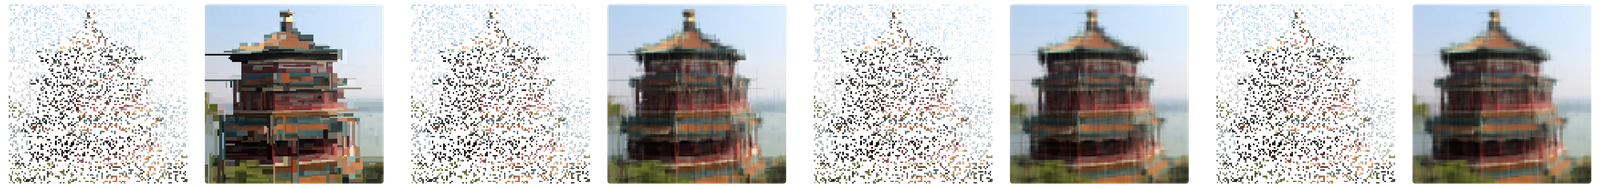

**Hỏi nhanh.** “Bootstrap $n$ mẫu từ $n$ mẫu gốc” nghĩa là gì?

- A. Rút $n$ lần không hoàn lại, tức là xáo trộn thứ tự
- B. Rút $n$ lần có hoàn lại từ $n$ mẫu gốc
- C. Giữ mỗi mẫu đúng một lần, chỉ đổi trọng số
- D. Rút ngẫu nhiên $n/2$ mẫu, không lặp lại

<details><summary>Đáp án</summary>

B. Rút $n$ lần có hoàn lại từ $n$ mẫu gốc

Rút có hoàn lại nên mỗi cây thấy một tập hơi khác nhau: có mẫu bị lặp, có mẫu vắng mặt. Rút không hoàn lại đủ $n$ lần thì chỉ là xáo trộn thứ tự, và cây nào cũng thấy đúng một bộ dữ liệu.

</details>

## Out-of-bag: validation miễn phí

Xác suất một mẫu không được chọn lần nào trong $n$ lần rút có hoàn lại là

$$\left(1 - \frac{1}{n}\right)^{n} \;\xrightarrow{\;n\to\infty\;}\; e^{-1} \approx 0.368.$$

Vậy mỗi cây “chưa thấy” khoảng 37% dữ liệu. Dự đoán mỗi mẫu bằng các cây không dùng nó, ta được điểm out-of-bag (OOB): một ước lượng gần như cross-validation mà không tốn thêm lần huấn luyện nào. Mỗi mẫu nhận phiếu đa số của riêng các cây không thấy nó; lỗi OOB là tỉ lệ mẫu bị đoán sai, tính theo mẫu chứ không theo từng phiếu.

**Hỏi nhanh.** Train có 1000 mẫu. Với một cây trong rừng, khoảng bao nhiêu mẫu nằm ngoài tập bootstrap của nó, và trong tập ấy có khoảng bao nhiêu mẫu **khác nhau**?

- A. 0 mẫu nằm ngoài, 1000 mẫu khác nhau
- B. 500 mẫu nằm ngoài, 500 mẫu khác nhau
- C. Khoảng 632 mẫu nằm ngoài, khoảng 368 mẫu khác nhau
- D. Khoảng 368 mẫu nằm ngoài, khoảng 632 mẫu khác nhau

<details><summary>Đáp án</summary>

D. Khoảng 368 mẫu nằm ngoài, khoảng 632 mẫu khác nhau

$(1 - 1/1000)^{1000} \approx e^{-1} \approx 0.368$, nên khoảng 368 mẫu không được rút lần nào. 1000 lượt rút rơi vào khoảng 632 mẫu khác nhau, phần còn lại là các lượt bị lặp.

</details>

## Ví dụ tính tay

Dữ liệu 5 mẫu, đánh số 1 đến 5, rừng có 3 cây với các tập bootstrap:

| Cây | Tập bootstrap | Mẫu out-of-bag |
|---|---|---|
| 1 | 1, 1, 3, 4, 4 | 2, 5 |
| 2 | 2, 2, 3, 5, 5 | 1, 4 |
| 3 | 1, 2, 2, 4, 5 | 3 |

Điểm OOB của mẫu 1 chỉ do cây 2 chấm, mẫu 3 chỉ do cây 3 chấm, và cứ thế. Với $n = 5$, xác suất một mẫu nằm ngoài một tập bootstrap là $(4/5)^5 \approx 0.33$, đã khá gần $0.368$.



Gộp kết quả cũng có hai cách, và chúng không luôn đồng ý. Ba cây cho xác suất lớp 1 của cùng một mẫu là $0.9$, $0.4$, $0.4$:

- Trung bình xác suất: $(0.9 + 0.4 + 0.4)/3 \approx 0.57$, dự đoán lớp 1.
- Bỏ phiếu: chỉ 1 trên 3 cây chọn lớp 1, dự đoán lớp 0.

Một cây rất chắc chắn thắng hai cây lưỡng lự. scikit-learn dùng cách thứ nhất, và khi cần xác suất để tính log loss hay AUC thì đó cũng là cách nên dùng.



## Các tham số

| Tham số | Ý nghĩa | Gợi ý |
|---|---|---|
| `n_estimators` | Số cây | Nhiều cây hơn thường bớt dao động; đo validation, RAM và thời gian trước khi tăng. |
| `max_features` | Số đặc trưng xét ở mỗi nút | Phân loại thường $\sqrt{d}$; nhỏ hơn thì cây đa dạng hơn |
| `min_samples_leaf` | Số mẫu tối thiểu ở lá | 1–5; tăng lên khi dữ liệu nhiễu |
| `max_depth` | Độ sâu | Thường để không giới hạn |

Biến thể Extra Trees (extremely randomized trees) chọn luôn ngưỡng ngẫu nhiên thay vì tìm ngưỡng tốt nhất: nhanh hơn, cây còn khác nhau hơn nữa, đôi khi tốt hơn trên dữ liệu nhiễu.

**Hỏi nhanh.** Muốn từng cây chính xác hơn, một bạn đặt `max_features` bằng toàn bộ $d$ feature. Lỗi tổng quát của rừng có xu hướng thế nào?

- A. Giảm, vì từng cây có lỗi tổng quát thấp hơn
- B. Tăng, vì mỗi cây không có đủ dữ liệu train
- C. Tăng, vì các cây trở nên rất giống nhau
- D. Không đổi, vì bootstrap đã đủ tạo khác biệt

<details><summary>Đáp án</summary>

C. Tăng, vì các cây trở nên rất giống nhau

Khi nút nào cũng được xét đủ $d$ feature, cây nào cũng chọn những feature mạnh nhất ở các tầng đầu. Các cây giống nhau hơn, nên $\rho$ tăng và phần $\rho\sigma^2$ không giảm được nữa. Đó chính là bagging thuần. Từng cây tốt hơn một chút không bù được việc mất đi sự đa dạng. Còn dữ liệu của mỗi cây thì không đổi.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q6.2(c)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=36)

</details>

## Tự nhìn một lần bootstrap

Đừng hiểu bootstrap là lấy một tập con không lặp. Với $n$ mẫu, mỗi cây rút $n$ lần **có hoàn lại**: một mẫu có thể xuất hiện nhiều lần, mẫu khác không xuất hiện lần nào. Ta nhìn ngay một lượt rút nhỏ trước khi dùng cả rừng.

In [ ]:
import numpy as np

rng_boot = np.random.default_rng(7)
draw = rng_boot.integers(0, 5, size=5)
seen = np.unique(draw)
oob = np.setdiff1d(np.arange(5), seen)
print("rút:", draw.tolist())
print("đã thấy:", seen.tolist(), "OOB:", oob.tolist())
probabilities = np.array([0.9, 0.4, 0.4])
print("trung bình:", round(float(probabilities.mean()), 3))
print("phiếu lớp 1:", int(np.sum(probabilities > 0.5)))

rút: [4, 3, 3, 4, 2]
đã thấy: [2, 3, 4] OOB: [0, 1]
trung bình: 0.567
phiếu lớp 1: 1


Đọc dòng “đã thấy”: số mẫu phân biệt có thể nhỏ hơn 5 dù đã rút đủ 5 lần. Với nhiều cây, mẫu 0 chỉ được chấm OOB bằng những cây không thấy mẫu 0. Có một cây không dùng nó không đủ để điểm OOB ổn định; cần nhiều cây và phải kiểm cảnh báo mẫu thiếu dự đoán OOB.



**Hỏi nhanh.** Một cây có tập bootstrap gồm các chỉ số [0, 0, 2, 3, 3], lấy từ dữ liệu có 5 mẫu. Những mẫu nào là OOB?

- A. Mẫu 0 và 3, vì bị rút lặp
- B. Mẫu 1 và 4
- C. Chỉ mẫu 4, vì mẫu cuối không được rút
- D. Không có, vì đã rút đủ 5 lần

<details><summary>Đáp án</summary>

B. Mẫu 1 và 4

Mẫu OOB là mẫu không xuất hiện lần nào trong các lượt rút. Mẫu 0 và 3 bị rút lặp, nhưng không vì thế mà thành OOB. Rút đủ 5 lần không có nghĩa là có đủ 5 mẫu khác nhau.

</details>

## Trung bình giảm nhiễu có điều kiện

Công thức phương sai ở trên giả sử các dự đoán có cùng phương sai $\sigma^2$ và mọi cặp có cùng tương quan $\rho$. Nó là một mô hình để thấy tác dụng của sự đa dạng, không phải cách dự đoán chính xác metric của bất kỳ rừng nào. Với các dự đoán thật, ta không được tự gán $\rho=0$ chỉ vì các cây được train bằng seed khác nhau: chúng vẫn dùng chung một nguồn dữ liệu và cùng những đặc trưng mạnh.

Random forest bớt biến động nhờ trung bình hóa, nhưng không chữa được việc toàn bộ dữ liệu train sai phân phối hay một cột rò rỉ target. Tăng số cây chủ yếu làm dự đoán ổn định hơn; validation có thể dao động và một rừng lớn vẫn overfit. Tăng `min_samples_leaf` hoặc hạn chế độ sâu làm từng cây mượt hơn, còn giảm `max_features` làm các cây đa dạng hơn nhưng cũng có thể làm từng cây yếu đi. Ta chọn cân bằng bằng validation.

**Hỏi nhanh.** 100 cây được học với 100 seed khác nhau. Có thể coi dự đoán của chúng là độc lập, tức $\rho = 0$, để tính phương sai theo công thức trên không?

- A. Được, vì seed khác nhau thì bootstrap khác nhau
- B. Được, nếu `max_features` đủ nhỏ
- C. Không được, vì seed không ảnh hưởng gì tới cây
- D. Không được, vì các cây học chung dữ liệu và chung những tín hiệu mạnh

<details><summary>Đáp án</summary>

D. Không được, vì các cây học chung dữ liệu và chung những tín hiệu mạnh

Seed khác nhau làm bootstrap và các feature được xét ở mỗi nút khác nhau, nên $\rho$ giảm. Nhưng các cây vẫn học từ cùng một bộ dữ liệu và cùng những tín hiệu mạnh, nên $\rho$ thật luôn dương. Lấy $\rho = 0$ sẽ hứa hẹn quá mức.

</details>

OOB rất tiện với các mẫu độc lập cùng phân phối. Nếu cùng một học sinh có nhiều bản ghi, cây không thấy một bản ghi nhưng có thể thấy các bản ghi khác của người đó. OOB theo hàng lúc này không thay thế group split. Với dự báo tương lai, bootstrap cũng không thay thế validation theo thời gian. Một lần chạy có OOB score cao chưa chứng minh mô hình dùng được ngoài lớp học.

## Dùng thư viện

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

X, y = load_breast_cancer(return_X_y=True)
tree = DecisionTreeClassifier(random_state=0)
forest = RandomForestClassifier(n_estimators=80, oob_score=True, n_jobs=1, random_state=0)
print("một cây:", round(cross_val_score(tree, X, y, cv=5).mean(), 3))
print("rừng:   ", round(cross_val_score(forest, X, y, cv=5).mean(), 3))
print("OOB:    ", round(forest.fit(X, y).oob_score_, 3))

một cây: 0.917
rừng:    0.963
OOB:     0.968


Rừng hơn một cây khoảng 4.6 điểm CV. OOB $0.968$ và CV $0.963$ là hai ước lượng khác nhau của cùng một thứ, và ở đây chúng gần nhau.



**Hỏi nhanh.** Điểm OOB của rừng là $0.968$, còn cross-validation 5 fold cho $0.963$. Hiểu chênh lệch này thế nào?

- A. OOB bị rò rỉ, vì cao hơn CV
- B. CV sai, vì OOB dùng nhiều dữ liệu hơn
- C. Hai cách lấy mẫu khác nhau, chênh nhỏ như vậy là bình thường
- D. Phải chọn số cây sao cho hai con số bằng nhau

<details><summary>Đáp án</summary>

C. Hai cách lấy mẫu khác nhau, chênh nhỏ như vậy là bình thường

OOB học rừng trên toàn bộ dữ liệu, rồi chấm mỗi mẫu bằng khoảng 37% số cây không thấy mẫu ấy. CV thì học 5 rừng, mỗi rừng trên 80% dữ liệu. Hai cách cho ra hai con số hơi khác nhau, và chênh 0.005 không nói lên chuyện rò rỉ. Với dữ liệu có nhóm hay theo thời gian, OOB tính theo từng hàng mới đáng ngờ.

</details>

## Khi đi thi

- **Baseline “khó hỏng”.** Không cần scale để chia ngưỡng; vẫn phải kiểm độ sâu, lá, split và overfitting. Trong 15 phút đầu của một bài dữ liệu bảng, random forest thường cho một con số tử tế.
- **Thêm cây không thay cho thử nghiệm.** Validation đứng yên khi tăng số cây nghĩa là lợi ích trung bình đã bão hòa; đổi `max_features`, feature hoặc dữ liệu mới là chỗ cần thử.
- **Thường thua gradient boosting** (bài 2.7) khi đã tinh chỉnh, nhưng là thành viên tốt trong ensemble vì sai theo kiểu khác.
- **Xác suất hơi “rụt rè”**: trung bình nhiều cây kéo xác suất về giữa. Nếu metric là log loss, cân nhắc hiệu chỉnh (calibration) trên validation.
- **`n_jobs=1`** trong notebook của bài để tránh tranh tài nguyên; tăng theo số nhân được cấp sau khi đo, vì overhead và băng thông bộ nhớ cũng ảnh hưởng tốc độ.
- **Kiểm tra nhanh tính tổng quát**: OOB score là một lần kiểm tra miễn phí trước khi chạy cross-validation đầy đủ.

## Tóm tắt

- Trung bình hóa nhiều mô hình giảm variance, nhưng chỉ khi chúng ít tương quan.
- Random forest = bagging + chọn ngẫu nhiên đặc trưng ở mỗi nút; mỗi cây sâu, cả rừng ổn định.
- Khoảng 37% dữ liệu nằm ngoài mỗi tập bootstrap, cho điểm OOB miễn phí.
- Thêm cây chủ yếu ổn định việc trung bình hóa, không thay thế kiểm validation; tham số quan trọng nhất là `max_features` và `min_samples_leaf`.

## Kiểm tra cuối bài

Mười câu kiểm cả cách hiểu, phép tính và quy trình. Câu sai chỉ ra phần cần đọc lại; hãy làm trước khi mở lời giải.

**Câu 1.** Có $n = 4$ mẫu train. Một cây rút 4 lần độc lập, đều xác suất, có hoàn lại. Xác suất một mẫu cụ thể không được rút lần nào là bao nhiêu?

- A. $(1/4)^4$
- B. 0
- C. $(3/4)^4$
- D. $1/4$

<details><summary>Đáp án</summary>

C. $(3/4)^4$

Mỗi lần rút, mẫu ấy có xác suất $3/4$ không được chọn. Bốn lần độc lập cho $(3/4)^4 = 81/256$. Rút 4 lần không bắt buộc phải có đủ 4 mẫu khác nhau.

</details>
**Câu 2.** Random forest chuẩn có dùng bootstrap. So với bagging các cây xét mọi feature ở mỗi nút, random forest giảm tương quan giữa các cây bằng cách nào?

- A. Ở mỗi nút, chỉ xét một tập con feature chọn ngẫu nhiên
- B. Bắt mọi cây học cùng một tập bootstrap
- C. Lấy dự đoán của cây trước làm target cho cây sau
- D. Chọn một feature duy nhất dùng chung cho cả rừng

<details><summary>Đáp án</summary>

A. Ở mỗi nút, chỉ xét một tập con feature chọn ngẫu nhiên

Chọn ngẫu nhiên feature ở mỗi nút khiến các cây không lúc nào cũng chọn cùng một feature mạnh nhất. Học tuần tự trên phần dư của cây trước là cơ chế của boosting.

</details>
**Câu 3.** Giả sử $B$ cây có phương sai dự đoán $\sigma^2 = 4$, và mọi cặp cây có cùng tương quan $\rho = 0.25$. Với $B = 20$, phương sai của trung bình dự đoán bằng bao nhiêu?

- A. 0.20
- B. 1.00
- C. 4.00
- D. 1.15

<details><summary>Đáp án</summary>

D. 1.15

$\operatorname{Var} = \sigma^2[\rho + (1-\rho)/B] = 4[0.25 + 0.75/20] = 1.15$. Thêm cây giảm được phần độc lập, nhưng không xóa được phần do tương quan.

</details>
**Câu 4.** Rừng 5 cây học trên 7 mẫu và gộp kết quả bằng đa số phiếu. Bảng ghi dự đoán của những cây không thấy từng mẫu.

| Mẫu | Thật | Dự đoán OOB của các cây không thấy mẫu |
|---|---|---|
| 1 | Không | Không |
| 2 | Không | Không, Có, Có |
| 3 | Có | Có |
| 4 | Có | Có |
| 5 | Không | Không |
| 6 | Có | Không |
| 7 | Có | Không, Không |

Lỗi OOB của rừng bằng bao nhiêu?

- A. $5/10$
- B. $3/7$
- C. $2/7$
- D. $4/7$

<details><summary>Đáp án</summary>

B. $3/7$

Phải gộp phiếu theo từng mẫu trước. Rừng đoán sai mẫu 2, 6 và 7, đúng bốn mẫu còn lại, nên lỗi là $3/7$. Ra $5/10$ là đếm từng dự đoán của từng cây.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q6.2(a)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=34)

</details>
**Câu 5.** Trong bảng của câu trước, có một cây đúng mọi mẫu OOB của nó, và một cây khác sai mọi mẫu. Khi dự đoán một mẫu mới, random forest chuẩn cho cây nào trọng số cao nhất?

- A. Cây đúng mọi mẫu OOB
- B. Cây có nhiều mẫu OOB nhất
- C. Không cây nào, các cây góp phần ngang nhau
- D. Cây sai mọi mẫu, nhưng đảo ngược dự đoán của nó

<details><summary>Đáp án</summary>

C. Không cây nào, các cây góp phần ngang nhau

Random forest lấy trung bình, hoặc bỏ phiếu, đều nhau qua mọi cây. Mỗi cây chỉ chấm vài mẫu OOB, nên “đúng hết” hay “sai hết” ở đây phần lớn là may rủi. Cho trọng số theo chất lượng của từng cây là ý tưởng của boosting (bài 2.7), nơi trọng số được học một cách có hệ thống.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q6.2(b)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=36)

</details>
**Câu 6.** Rừng hồi quy học giá nhà từ những căn có giá 1 đến 5 tỷ. Một căn mới rộng gấp đôi căn lớn nhất trong train. Rừng sẽ dự đoán ra sao?

- A. Khoảng 10 tỷ, vì rừng kéo dài xu hướng theo diện tích
- B. Không quá 5 tỷ, vì đó là trung bình của các lá
- C. Số nào cũng có thể, vì mỗi cây kéo dài theo một hướng riêng
- D. Báo lỗi, vì giá trị nằm ngoài vùng train

<details><summary>Đáp án</summary>

B. Không quá 5 tỷ, vì đó là trung bình của các lá

Mỗi cây dự đoán trung bình target của một lá, nên kết quả luôn nằm trong khoảng giá của train. Trung bình của các cây cũng vậy. Rừng không đoán ra ngoài vùng đã thấy, giống một cây đơn (bài 2.5). Khi test có thể vượt xa train, ta cần kiểm bằng một tập validation có cấu trúc tương tự, hoặc dùng thêm mô hình tuyến tính.

</details>
**Câu 7.** Mỗi bệnh nhân có 4 bản ghi, và mục tiêu là dự đoán cho bệnh nhân mới. Nhưng OOB tính theo hàng vẫn để một bản ghi được chấm bởi những cây đã học các bản ghi khác của cùng người. Ta nên đánh giá bổ sung thế nào?

- A. Để riêng theo bệnh nhân, rồi chấm cả quy trình
- B. Chỉ cần tăng số cây, để hàng nào cũng có nhiều dự đoán OOB hơn
- C. Chỉ cần tăng `min_samples_leaf`, để cấm trùng bệnh nhân
- D. Dùng StratifiedKFold theo từng hàng thay cho chia theo nhóm

<details><summary>Đáp án</summary>

A. Để riêng theo bệnh nhân, rồi chấm cả quy trình

OOB thông thường tính theo hàng, nên chưa mô phỏng được tình huống gặp người mới. Độ sâu của cây, số cây hay việc giữ tỉ lệ lớp đều không thay được cho việc chia theo bệnh nhân.

</details>
**Câu 8.** Tăng `n_estimators` từ 100 lên 1000. Accuracy trên train tăng từ 99.2% lên 99.8%, trên validation vẫn đứng ở 87.3%, còn thời gian chạy tăng gấp 10. Nhận định nào phù hợp?

- A. Validation đứng yên chứng tỏ phải tăng độ sâu của cây
- B. Cứ tăng số cây tới khi train đạt 100%, rồi chọn theo train
- C. Train tăng 0.6 điểm, nên sau này validation cũng sẽ tăng
- D. Lợi ích của việc thêm cây đã bão hòa, nên thử yếu tố khác

<details><summary>Đáp án</summary>

D. Lợi ích của việc thêm cây đã bão hòa, nên thử yếu tố khác

Từ khoảng vài trăm cây trở đi, phép lấy trung bình đã ổn định. Thêm cây làm chi phí tăng mười lần mà validation không nhích. Thêm cây cũng không làm rừng overfit thêm. Chỗ cần thử là `max_features`, độ sâu, feature hay dữ liệu, mỗi lần đổi một thứ có kiểm soát.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 2](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=3)

</details>
**Câu 9.** `classes_` của rừng là `["fraud", "normal"]`, và metric cần score của lớp fraud. Dòng nào lấy đúng score ấy?

- A. `predict_proba(X)[:, 0]`
- B. `predict_proba(X)[:, 1]`
- C. `predict(X) == "fraud"`, để giữ đủ thứ tự score
- D. Lấy cột có nhiều score trên 0.5 hơn

<details><summary>Đáp án</summary>

A. `predict_proba(X)[:, 0]`

Fraud nằm ở vị trí 0 trong `classes_`. Nhãn sau `predict` không còn giữ mức score cần cho metric xếp hạng hay metric xác suất.

</details>
**Câu 10.** Rừng tìm ra một cột chứa sẵn đáp án của validation, và điểm rất cao. Điểm cao ấy chứng tỏ điều gì?

- A. Rừng đã học được quy luật tốt hơn mọi mô hình khác
- B. Gần như chắc chắn có rò rỉ, phải sửa dữ liệu
- C. Nên thêm cây cho điểm ổn định hơn nữa
- D. Nên tăng `max_features` để cột ấy được dùng nhiều hơn

<details><summary>Đáp án</summary>

B. Gần như chắc chắn có rò rỉ, phải sửa dữ liệu

Gộp nhiều mô hình cũng không sửa được một feature vốn không có sẵn lúc dự đoán thật.

</details>
## Đọc thêm

- James, Witten, Hastie, Tibshirani — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), mục 8.2. Bagging, random forest và OOB với ví dụ đọc kết quả.
- Géron — *Hands-On Machine Learning*, chương 7. Ensemble, bagging, random forest và Extra Trees bằng scikit-learn.
- Galton (1907) — *Vox Populi*, Nature 75. Câu chuyện đám đông đoán cân nặng con bò: trung bình nhiều phỏng đoán độc lập chính xác hơn từng người.
- [Breiman — Random Forests](https://www.stat.berkeley.edu/~breiman/randomforest2001.pdf). Bài gốc về random forest, sự đa dạng và out-of-bag.
- [scikit-learn — Forests of randomized trees](https://scikit-learn.org/stable/modules/ensemble.html#forest). Tham số, phân loại bằng trung bình xác suất và chi phí song song.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0).